# Fashion products: exploratory data analysis

* Imports and load data

In [ ]:
from pathlib import Path
from collections import Counter
from wordcloud import WordCloud
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import sys


data_file = Path.home() / "Desktop" / "IRWA_project" / "Data" / "processed_fashion_products.json"
df = pd.read_json(data_file)
print("Loaded", len(df), "products")

Loaded 28080 products


* Dataset overview

This summarizes the dataset and checks its basic structure.

In [7]:
# general info about the columns (types and nulls)
df.info()
df.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   actual_price           28080 non-null  str    
 1   average_rating         28080 non-null  str    
 2   brand                  28080 non-null  str    
 3   category               28080 non-null  str    
 4   description            28080 non-null  str    
 5   discount               28080 non-null  str    
 6   out_of_stock           28080 non-null  bool   
 7   pid                    28080 non-null  str    
 8   product_details        28080 non-null  object 
 9   seller                 28080 non-null  str    
 10  selling_price          28080 non-null  str    
 11  sub_category           28080 non-null  str    
 12  title                  28080 non-null  str    
 13  url                    28080 non-null  str    
 14  processed_title        28080 non-null  object 
 15  processed_des

,actual_price,average_rating,brand,category,description,discount,out_of_stock,pid,product_details,seller,...,title,url,processed_title,processed_description,is_available,selling_price_value,actual_price_value,discount_percent,average_rating_value,processed_metadata
0,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,69% off,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,...,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,921.0,2999.0,69.0,3.9,"[york, bottomwear, elast, side, pocket, cotton..."
1,"1,499",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,66% off,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,...,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,499.0,1499.0,66.0,3.9,"[york, bottomwear, drawstr, elast, side, pocke..."
2,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,68% off,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,...,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,931.0,2999.0,68.0,3.9,"[york, bottomwear, elast, side, pocket, cotton..."
3,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,69% off,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,...,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,911.0,2999.0,69.0,3.9,"[york, bottomwear, elast, side, pocket, cotton..."
4,"2,999",3.9,York,Clothing and Accessories,Yorker trackpants made from 100% rich combed c...,68% off,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,...,"Solid Women Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...,"[solid, women, brown, grey, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",True,943.0,2999.0,68.0,3.9,"[york, bottomwear, drawstr, elast, side, pocke..."


* Text fields and vocabulary

These plots show how much text is available and which terms are common.

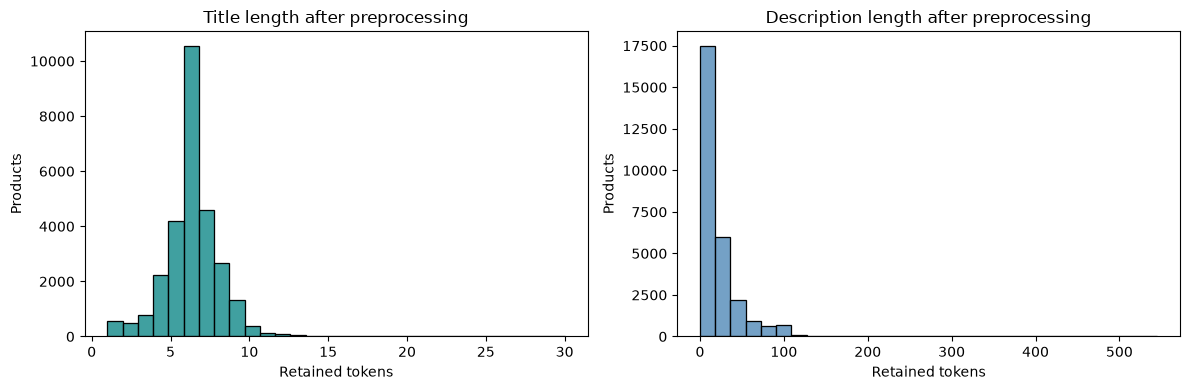

,count,mean,std,min,25%,50%,75%,max
title_token_count,28080.0,6.08,1.87,1.0,5.0,6.0,7.0,30.0
description_token_count,28080.0,18.70,26.54,0.0,0.0,9.0,29.0,545.0


In [8]:
# count how many tokens we kept after preprocessing in title and description
title_counts = []
desc_counts = []
for i in range(len(df)):
    title = df["processed_title"].iloc[i]
    desc = df["processed_description"].iloc[i]
    # some rows could be empty or not a list, in that case we count 0
    if isinstance(title, list):
        title_counts.append(len(title))
    else:
        title_counts.append(0)
    if isinstance(desc, list):
        desc_counts.append(len(desc))
    else:
        desc_counts.append(0)

df["title_token_count"] = title_counts
df["description_token_count"] = desc_counts

# histograms of both lengths
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["title_token_count"], bins=30, ax=axes[0], color="teal")
axes[0].set_title("Title length after preprocessing")
axes[0].set_xlabel("Retained tokens")
axes[0].set_ylabel("Products")

sns.histplot(df["description_token_count"], bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Description length after preprocessing")
axes[1].set_xlabel("Retained tokens")
axes[1].set_ylabel("Products")
plt.tight_layout()
plt.show()

# summary statistics
display(df[["title_token_count", "description_token_count"]].describe().T.round(2))

Total retained title + description tokens: 695782
Vocabulary size (unique stemmed tokens): 4875


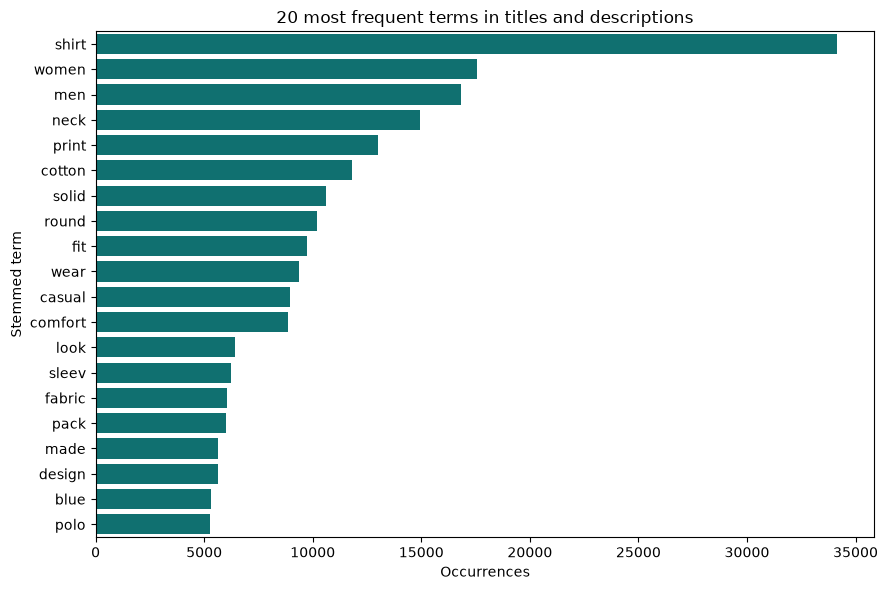

In [ ]:
#  we put all the tokens of titles and descriptions in a single list
text_tokens = []
for column in ["processed_title", "processed_description"]:
    for value in df[column]:
        if isinstance(value, list):
            for token in value:
                text_tokens.append(token)

term_counts = Counter(text_tokens)
vocabulary = set(text_tokens)

print("Total retained title + description tokens:", len(text_tokens))
print("Vocabulary size:", len(vocabulary))

# top 20 most frequent terms
top_terms = pd.DataFrame(term_counts.most_common(20), columns=["Stemmed term", "Occurrences"])
plt.figure(figsize=(9, 6))
sns.barplot(data=top_terms, x="Occurrences", y="Stemmed term", color="teal")
plt.title("20 most frequent terms in titles and descriptions")
plt.tight_layout()
plt.show()

* Top Sub-categories and brands

These counts show which product types and brands appear most often.

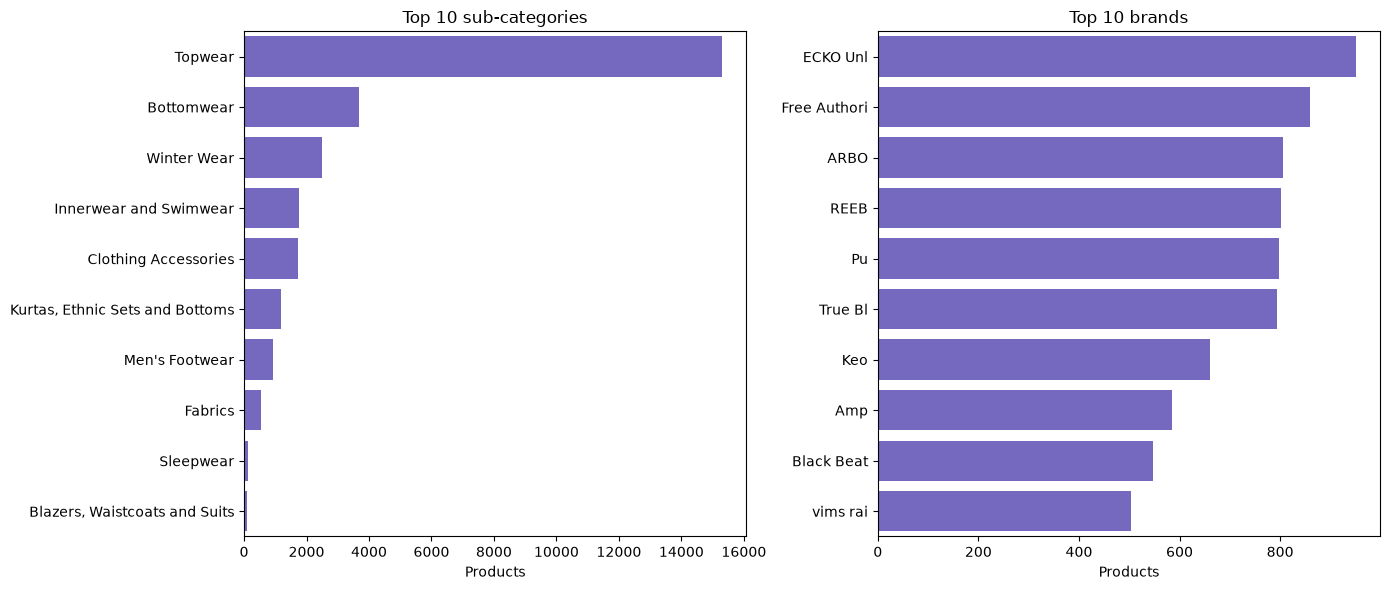

In [10]:
# small function to get the top n values of a column
# (we remove empty strings so they don't appear in the plot)
def top_counts(column, n=10):
    values = df[column].dropna().astype(str).str.strip()
    values = values[values != ""]
    return values.value_counts().head(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# sub-categories
counts = top_counts("sub_category")
sns.barplot(x=counts.values, y=counts.index, ax=axes[0], color="slateblue")
axes[0].set_title("Top 10 sub-categories")
axes[0].set_xlabel("Products")
axes[0].set_ylabel("")

# brands
counts = top_counts("brand")
sns.barplot(x=counts.values, y=counts.index, ax=axes[1], color="slateblue")
axes[1].set_title("Top 10 brands")
axes[1].set_xlabel("Products")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

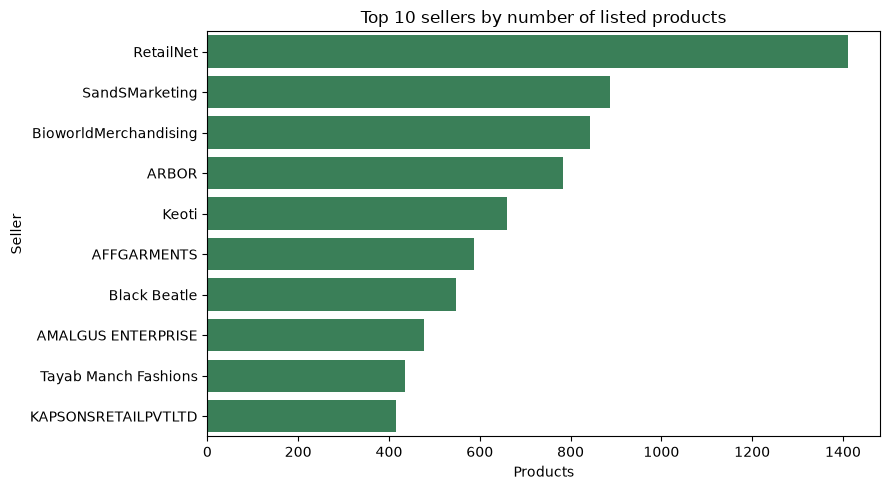

In [11]:
# same thing but for the sellers
seller_counts = top_counts("seller", n=10)
plt.figure(figsize=(9, 5))
sns.barplot(x=seller_counts.values, y=seller_counts.index, color="seagreen")
plt.title("Top 10 sellers by number of listed products")
plt.xlabel("Products")
plt.ylabel("Seller")
plt.tight_layout()
plt.show()

* Commercial attributes

These plots summarize availability, prices, discounts, and ratings.

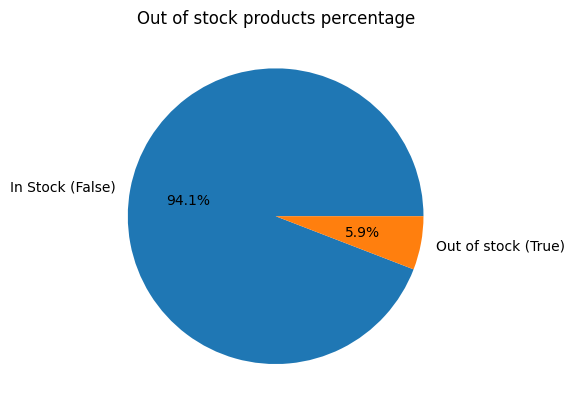

In [ ]:
# proportion of products in stock vs out of stock
stock_counts = df["is_available"].value_counts()

plt.pie(stock_counts, labels=["In Stock ", "Out of stock"], autopct="%1.1f%%")
plt.title("Out of stock products percentage", fontsize=12)
plt.show()

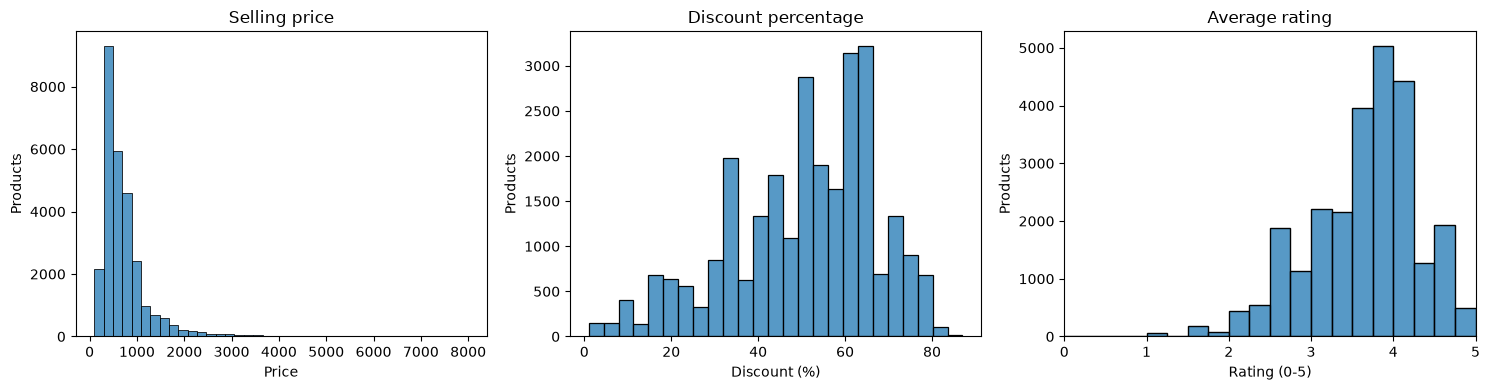

,selling_price_value,discount_percent,average_rating_value
count,28078.000000,27225.000000,25819.000000
mean,705.635088,50.256896,3.627724
std,549.681489,16.887287,0.663429
min,99.000000,1.000000,1.000000
25%,390.000000,40.000000,3.200000
50%,545.000000,53.000000,3.800000
75%,820.000000,63.000000,4.100000
max,7999.000000,87.000000,5.000000


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# selling price
prices = df["selling_price_value"].dropna()
sns.histplot(prices, bins=40, ax=axes[0])
axes[0].set_title("Selling price")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Products")

# discount
discounts = df["discount_percent"].dropna()
sns.histplot(discounts, bins=25, ax=axes[1])
axes[1].set_title("Discount percentage")
axes[1].set_xlabel("Discount (%)")
axes[1].set_ylabel("Products")

# rating (goes from 0 to 5, bins of 0.25)
ratings = df["average_rating_value"].dropna()
sns.histplot(ratings, bins=np.arange(0, 5.25, 0.25), ax=axes[2])
axes[2].set_title("Average rating")
axes[2].set_xlabel("Rating (0-5)")
axes[2].set_ylabel("Products")
axes[2].set_xlim(0, 5)

plt.tight_layout()
plt.show()

display(df[["selling_price_value", "discount_percent", "average_rating_value"]].describe())

* Word cloud

The word cloud gives a visual overview of common description terms.

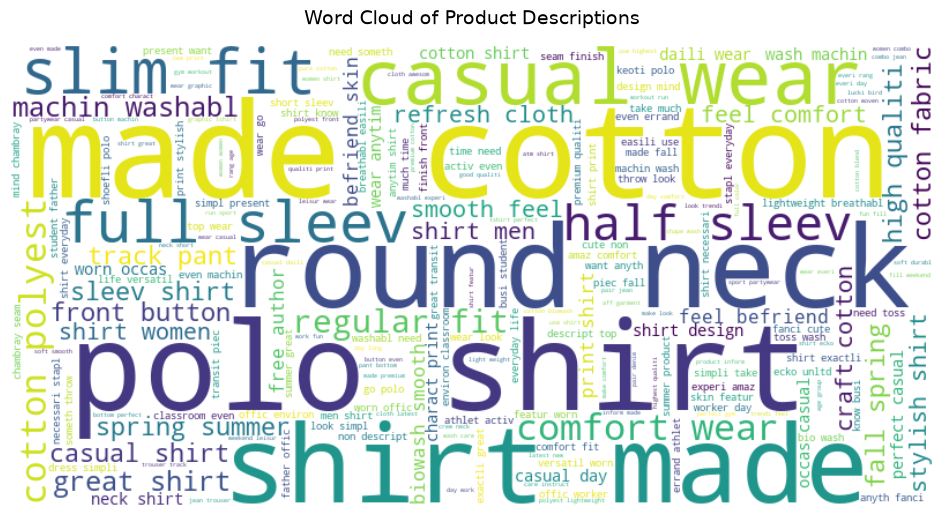

In [13]:
# join all the description tokens in one big string for the wordcloud
all_words = []
for tokens in df["processed_description"].dropna():
    if isinstance(tokens, list):
        all_words.extend(tokens)
all_text = " ".join(all_words)

wordcloud = WordCloud(width=800, height=400, background_color="white", colormap="viridis").generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Product Descriptions", fontsize=14, pad=15)
plt.show()

* Exploratory named-entity recognition

NER finds possible names in a sample; its results may not always be accurate.

In [14]:
# only needed the first time (downloads the small english model)
!{sys.executable} -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 69.0 MB/s  0:00:00m0:00:01

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


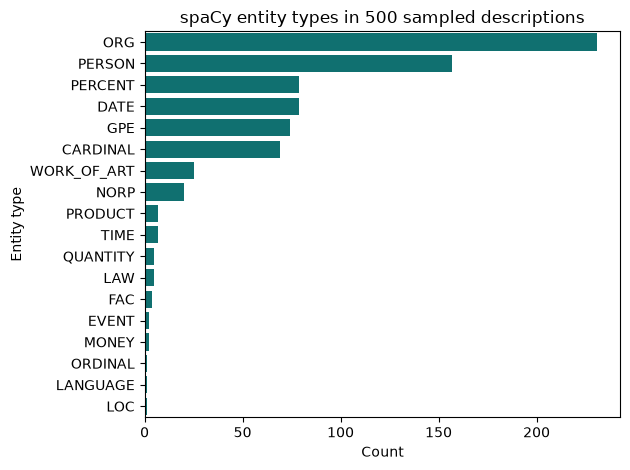

Most frequent entity examples:


,Entity,Type,Count
0,100%,PERCENT,53
1,kurta,GPE,14
2,60%,PERCENT,12
3,40%,PERCENT,11
4,Arbour,PERSON,9
5,two,CARDINAL,9
6,all day,DATE,8
7,2,CARDINAL,8
8,Cotton,GPE,8
9,3,CARDINAL,8


In [18]:
nlp = spacy.load("en_core_web_sm")

# we only use 500 random descriptions because running spacy on all of them is very slow
descriptions = df["description"].dropna()
ner_sample = descriptions.sample(n=500)

# count the entity types and also the entities themselves
type_counts = Counter()
entity_counts = Counter()
for doc in nlp.pipe(ner_sample, batch_size=32):
    for ent in doc.ents:
        type_counts[ent.label_] += 1
        text = ent.text.strip()
        if text != "":
            entity_counts[(text, ent.label_)] += 1

# plot of the entity types
entity_table = pd.DataFrame(type_counts.most_common(), columns=["Entity type", "Count"])
sns.barplot(data=entity_table, x="Count", y="Entity type", color="teal")
plt.title("spaCy entity types in 500 sampled descriptions")
plt.tight_layout()
plt.show()

# table with the 15 most common entities
print("Most frequent entity examples:")
rows = []
for (text, label), count in entity_counts.most_common(15):
    rows.append([text, label, count])
display(pd.DataFrame(rows, columns=["Entity", "Type", "Count"]))